In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

In [2]:
wine = load_wine()
X = wine.data
y = wine.target

wine.target_names

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [3]:
X.shape

(178, 13)

In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.30,
                                                random_state = 42, stratify = y)
cv = StratifiedKFold(n_splits = 5,shuffle = True, random_state = 42)



In [5]:
pipeline_svm = Pipeline(
    [
        ('scaler',StandardScaler()),
        ("svc", SVC())
    ]
)
param_grid = [
    
    {
        "svc__kernel": ["linear"],
        "svc__C": [
            0.01,
            0.1,
            1,
            10,
            100
        ]
    },
    
    {
        "svc__kernel": ["rbf"],
        "svc__C": [
            0.01,
            0.1,
            1,
            10,
            100
        ],
        "svc__gamma": [
            0.001,
            0.01,
            0.1,
            1,
            10
        ]
    },
    
    {
        "svc__kernel": ["poly"],
        "svc__C": [
            0.1,
            1,
            10
        ],
        "svc__degree": [
            2,
            3,
            4
        ],
        "svc__gamma": ["scale"],
        "svc__coef0": [1]
    }
]


In [6]:
grid_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

grid_svm.fit(
    X_train,
    y_train
)

grid_svm.best_params_
grid_svm.best_score_

np.float64(0.992)

In [7]:
mejor_svm = grid_svm.best_estimator_


In [8]:
modelo_logistico = Pipeline(
    [
        ("scaler",StandardScaler()),
        ("logistic",LogisticRegression(max_iter = 10000))
    ]
)

modelo_logistico.fit(X_train,y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=10000))])

In [9]:
pred_svm = mejor_svm.predict(X_test)
pred_log = modelo_logistico.predict(X_test)

acc_svm = accuracy_score(y_test,pred_svm)
acc_svm

0.9629629629629629

In [10]:
acc_log = accuracy_score(y_test,pred_log)
acc_log

0.9814814814814815

In [11]:
from sklearn.model_selection import cross_val_score
cv_log =cross_val_score(modelo_logistico,X_train,y_train,cv=cv,scoring = "accuracy")
cv_log.mean()

np.float64(0.984)

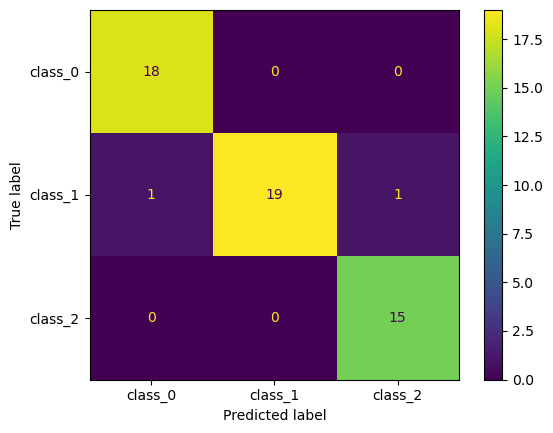

In [12]:
cm_svm = confusion_matrix(y_test,pred_svm)

ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels = wine.target_names
                       ,).plot()

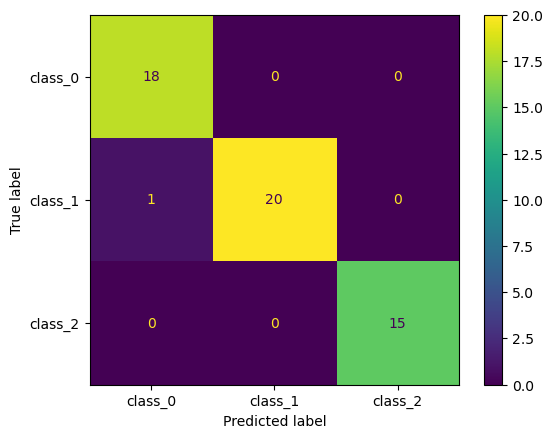

In [13]:
cm_log = confusion_matrix(y_test,pred_log)

ConfusionMatrixDisplay(confusion_matrix=cm_log, display_labels = wine.target_names
                       ,).plot()

In [14]:
print(
    classification_report(y_test,pred_svm, target_names = wine.target_names)
)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.90      0.95        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



In [15]:
print(
    classification_report(y_test,pred_log, target_names = wine.target_names)
)

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.95      0.98        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



In [16]:
m = np.linspace(-4,4,400)
loss_log = np.log(1+np.exp(-m))
loss_hinge = np.maximum(0,1-m)


In [17]:
prob_log = modelo_logistico.predict_proba(X_test)
prob_log[:5]

array([[9.90734414e-01, 8.83183589e-03, 4.33749989e-04],
       [2.26955261e-03, 9.96689670e-01, 1.04077696e-03],
       [9.99963345e-01, 9.68794813e-06, 2.69670837e-05],
       [9.99053535e-01, 1.63087572e-04, 7.83377491e-04],
       [7.54731765e-01, 2.43282814e-01, 1.98542115e-03]])

In [18]:
np.argmax(prob_log[:5], axis = 1)

array([0, 1, 0, 0, 0])

In [19]:
logloss_log = log_loss(
    y_test, prob_log
)

logloss_log

0.07779916204259246

# Ejercicios

## 16.24.1 Ejercicio 1. Comparar predicciones
Identifica las observaciones del conjunto de prueba para las cuales la SVM y la regresión logística producen predicciones diferentes.

¿Cuántas son? 1 la observación 11

In [20]:
vec_comp = np.array([pred_log==pred_svm])[0]
print(pd.DataFrame({"comp":vec_comp})["comp"].value_counts())
vec_comp

comp
True     53
False     1
Name: count, dtype: int64


array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True])

## 16.24.2 Ejercicio 2. Comparar las pérdidas
Calcula la pérdida logística y la pérdida hinge para:

m =[-3,-2,-1,0,1,2,3]

Construye una tabla y explica qué ocurre cuando me es mayor o igual a 1

RESPUESTA: Lo que pasa cuando m es mayo o igual a 1 es que loss hinge se vuelve cero y el loss logaritmico empieza a tener perdidas menores a 1 es decir la perdida disminuye.

In [21]:
m = np.arange(-3,4,1)
loss_log = np.log(1+np.exp(-m))
loss_hinge = np.maximum(0,1-m)

df = pd.DataFrame({"m":m,"loss_log":loss_log,"loss_hinge": loss_hinge})
df


,m,loss_log,loss_hinge
0,-3,3.048587,4
1,-2,2.126928,3
2,-1,1.313262,2
3,0,0.693147,1
4,1,0.313262,0
5,2,0.126928,0
6,3,0.048587,0


## 16.24.3 Ejercicio 3. Probabilidades de regresión logística
Selecciona las primeras diez observaciones del conjunto de prueba.

Obtén sus probabilidades estimadas.

Para cada observación identifica:

la clase verdadera;
la clase predicha;
la probabilidad más alta;
si la clasificación fue correcta.

In [22]:
pred_log_test = modelo_logistico.predict(X_test[0:10])
pred_log_proba_test = modelo_logistico.predict_proba(X_test[0:10])
y_test10 = y_test[0:10]

print("Probabilidad predicha mas alta\n",np.max(pred_log_proba_test))
print("\n")
print("Clase predicha\n",pred_log_test)
print("\n")
print("Clase verdadera\n", y_test10)
print("\n")
print("ver si fue correcta\n", [pred_log_test==y_test10])

Probabilidad predicha mas alta
 0.9999633449681439


Clase predicha
 [0 1 0 0 0 0 2 1 1 2]


Clase verdadera
 [0 1 0 0 0 0 2 1 1 2]


ver si fue correcta
 [array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])]


## 16.24.4 Ejercicio 4. Regularización en regresión logística
Ajusta regresiones logísticas utilizando:

c = [0.001,0.01,0.1,1,10,100]

Utiliza validación cruzada sobre el conjunto de entrenamiento.

No utilices X_test para seleccionar 
.

In [23]:
c_vals = [0.001,0.01,0.1,1,10,100]

for c in c_vals:
    modelo_logistico = Pipeline(
        [
            ("scaler",StandardScaler()),
            ("logistic",LogisticRegression(C = c, max_iter = 10000))
        ]
    )
    
    modelo_logistico.fit(X_train,y_train)
    print(c)
    print(accuracy_score(y_train,modelo_logistico.predict(X_train)))

0.001
0.7338709677419355
0.01
0.9919354838709677
0.1
0.9919354838709677
1
1.0
10
1.0
100
1.0


In [24]:
from sklearn.datasets import fetch_covtype

data = fetch_covtype()
X = pd.DataFrame(data.data,
                columns = data.feature_names)

y = pd.Series(data.target, name = "Cover_Type")
print(X.shape)
#print(X)
print(y.value_counts)

(581012, 54)
        Elevation  Aspect  Slope  Horizontal_Distance_To_Hydrology  \
0          2596.0    51.0    3.0                             258.0   
1          2590.0    56.0    2.0                             212.0   
2          2804.0   139.0    9.0                             268.0   
3          2785.0   155.0   18.0                             242.0   
4          2595.0    45.0    2.0                             153.0   
...           ...     ...    ...                               ...   
581007     2396.0   153.0   20.0                              85.0   
581008     2391.0   152.0   19.0                              67.0   
581009     2386.0   159.0   17.0                              60.0   
581010     2384.0   170.0   15.0                              60.0   
581011     2383.0   165.0   13.0                              60.0   

        Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Roadways  \
0                                  0.0                            510.0

In [25]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.01,train_size =0.03,random_state = 42, stratify = y)


In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle = True, random_state = 42)
param_grid = [
    {
    "svc__kernel": ["rbf"],
    "svc__C": [0.001,0.01,0.1,1,10,100],
    "svc__gamma": [0.001,0.01,0.1,1,10]
},
        {
    "svc__kernel": ["linear"],
    "svc__C": [0.001,0.01,0.1,1,10,100]
},
     {"svc__kernel": ["poly"],
    "svc__C": [0.1,1,10],
    "svc__degree": [2,3,4],
    "svc__gamma": ["scale"]
        }
             ]
modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel = "rbf"))
    ]
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))